# 1.1 — First Scikit-Learn Model: Linear Regression

**Objective:** Build a linear regression model using Scikit-Learn to predict house prices from house sizes.

**Concepts covered:**
- Features (`X`) and target (`y`)
- Creating a `LinearRegression` estimator
- Training with `fit()`
- Making predictions with `predict()`
- Understanding the learned coefficient (`coef_`) and intercept (`intercept_`)

**Dataset:** A small example dataset of house sizes and prices.

**Important note:** Scikit-Learn's `LinearRegression` uses ordinary least squares, not gradient descent.


In [3]:
import numpy as np
from sklearn.linear_model import LinearRegression

In [4]:
# Features: house sizes
X = np.array([
    [50],
    [60],
    [80],
    [100],
    [120]
])

# Targets: house prices in lakh taka
y = np.array([25, 30, 40, 50, 60])

#Create a model
model = LinearRegression()

#Train the model
model.fit(X, y)

#Predict the price of a 90 m^2 house
prediction = model.predict([[90]])

In [5]:
print(f"Prediction : {prediction}")
print(f"Coefficient (w) : {model.coef_}")
print(f"Bias/Intercept (b) : {model.intercept_}")

Prediction : [45.]
Coefficient (w) : [0.5]
Bias/Intercept (b) : 7.105427357601002e-15


## 1.2 — Understanding Features, Targets, and Dataset Shapes

**Objective:** Understand how supervised-learning datasets are represented in NumPy and Scikit-Learn.

**Concepts covered:**
- Samples (rows) and features (columns)
- Input features (`X`) and target (`y`)
- The shape of the feature matrix: `(n_samples, n_features)`
- The usual shape of a single-output target array: `(n_samples,)`
- How adding a feature changes the dataset shape

**Key takeaway:** Each row of `X` represents one sample, and each column represents one feature. The target `y` contains the value the model learns to predict for each sample.

In [6]:
import numpy as np

In [7]:
# Features: size, bedrooms, age
X = np.array([
    [50, 2, 10],
    [70, 3, 5],
    [90, 3, 2],
    [120, 4, 1]
])

# Target: house prices
y = np.array([25, 35, 45, 60])

print(f"X shape : {X.shape}")
print(f"y shape : {y.shape}")

X shape : (4, 3)
y shape : (4,)


## 1.3 — Understanding the Scikit-Learn Estimator API

**Objective:** Understand how Scikit-Learn objects are created, trained, and used.

**Concepts covered:**
- Estimators, predictors, and transformers
- The purpose of `fit()` and `predict()`
- Learned attributes such as `coef_` and `intercept_`
- The difference between creating a model and training it
- Estimator: An object that learns from data, typically through fit().
- Predictor: An object that makes predictions using predict().
- Transformer: An object that transforms data using transform().

In [8]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Training data
X = np.array([[50], [60], [80], [100], [120]])
y = np.array([25, 30, 40, 50, 60])

model = LinearRegression()

model.fit(X, y)

predictions = model.predict([[90], [110]])

print(f"Predictions: {predictions}")
print(f"Coefficient: {model.coef_}")
print(f"Intercept: {model.intercept_}")
print(f"Number of features: {model.n_features_in_}")

Predictions: [45. 55.]
Coefficient: [0.5]
Intercept: 7.105427357601002e-15
Number of features: 1


## 1.4 — Transformers: `transform()` and `fit_transform()`

**Objective:** Understand how Scikit-Learn transformers learn transformation rules and apply them to data.

**Concepts covered:**
- What a transformer does
- `StandardScaler`
- `fit()`, `transform()`, and `fit_transform()`
- Why the scaler learns statistics from training data
- Why the same fitted scaler should be used on new data

- **`StandardScaler()`**: Creates a transformer that standardizes numerical features.
- **`fit(X)`**: Learns the mean and scaling factor of each feature.
- **`transform(X)`**: Transforms data using previously learned statistics.
- **`fit_transform(X)`**: Learns statistics and transforms the data in one step.
- **`scaler.mean_`**: Stores learned feature means.
- **`scaler.scale_`**: Stores learned scaling factors.

**Example:**
```python
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
```

**Key rule:** Fit on training data; use the same fitted scaler to transform test or new data.

In [9]:
import numpy as np
from sklearn.preprocessing import StandardScaler

In [10]:
#Two features: house size and number of bedrooms
X_before = np.array([
    [50, 2],
    [80, 3],
    [120, 4],
    [100, 3]
])

#Create the transformer
scaler = StandardScaler()

#Learn the statistics and transform the data
X_scaled = scaler.fit_transform(X)

print(f"X originally :")
print(X_before)
print("\n")
print(f"X after scaling :")
print(X_scaled)

print("\nLearned means:")
print(scaler.mean_)

print("\nLearned standard deviations:")
print(scaler.scale_)

X originally :
[[ 50   2]
 [ 80   3]
 [120   4]
 [100   3]]


X after scaling :
[[-1.2493901 ]
 [-0.85895569]
 [-0.07808688]
 [ 0.70278193]
 [ 1.48365074]]

Learned means:
[82.]

Learned standard deviations:
[25.61249695]


## 1.5 — Hyperparameters vs. Learned Parameters

### 1. Definitions

- **Hyperparameters:** Settings chosen before training that control model behavior.
- **Learned parameters:** Values estimated by the model from training data during `fit()`.

### 2. Example: `LinearRegression`

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression(fit_intercept=True)
model.fit(X, y)

print(model.coef_)
print(model.intercept_)
```

- `fit_intercept=True`: Hyperparameter chosen by the user.
- `coef_`: Learned coefficient.
- `intercept_`: Learned intercept.

### 3. Why Do Hyperparameters Matter?

```python
model1 = LinearRegression(fit_intercept=True)
model2 = LinearRegression(fit_intercept=False)
```

- **Model 1:** Learns the coefficient and intercept.
- **Model 2:** Learns the coefficient while forcing the intercept to zero.

The hyperparameter choice changes how the model fits the data.

**Key takeaway:** Hyperparameters control aspects of model behavior; learned parameters are estimated from data.

**Note:** `coef_` and `intercept_` become available after fitting the model.

| Situation | Setting | Reason |
|---|---|---|
| House-price prediction | `True` | No reason to assume the price must be zero when all features are zero. |
| Student-score prediction | `True` | The relationship may have a nonzero intercept. |
| Predicting distance from time at a constant speed, measured from the starting point | Possibly `False` | At time zero, distance is physically zero. |
| A model whose relationship is known to pass through the origin | `False` | Enforces that known constraint. |

In [11]:
from sklearn.linear_model import LinearRegression

model = LinearRegression(fit_intercept=True)
model.fit(X, y)

print(model.coef_)
print(model.intercept_)

[0.5]
7.105427357601002e-15


In [12]:
from sklearn.linear_model import SGDRegressor

model = SGDRegressor(
    learning_rate="constant",
    eta0=0.01,
    max_iter=1000
)

model.fit(X, y)

SGDRegressor(learning_rate='constant')

In [13]:
import numpy as np
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3]])
y = np.array([3, 5, 7])

model1 = LinearRegression(fit_intercept=True)
model1.fit(X, y)

model2 = LinearRegression(fit_intercept=False)
model2.fit(X, y)

print("Model 1:", model1.coef_, model1.intercept_)
print("Model 2:", model2.coef_, model2.intercept_)

Model 1: [2.] 1.0000000000000009
Model 2: [2.42857143] 0.0


## 1.6.1 — Built-in Toy Datasets

Scikit-Learn provides small, ready-to-use datasets for practicing machine learning without downloading external files.

### Example: `load_diabetes()`

### Key concepts

- `data.data`: Contains the input features (`X`).
- `data.target`: Contains the target values (`y`).
- `data.feature_names`: Contains the names of the features.
- `load_diabetes()`: Loads a built-in regression dataset.

**Dataset shape:**
- `X.shape`: `(442, 10)`
- `y.shape`: `(442,)`

**Interpretation:** The dataset contains 442 samples, 10 features per sample, and one target value per sample. The target measures diabetes disease progression, not a diabetes diagnosis.

**When to use:** Practicing machine learning algorithms with an existing dataset.

In [14]:
from sklearn.datasets import load_diabetes

data = load_diabetes()

X = data.data
y = data.target

print(f"X shape : {X.shape}")
print(f"y shape : {y.shape}")
print(f"Feature Names : {data.feature_names}")

X shape : (442, 10)
y shape : (442,)
Feature Names : ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


## 1.6.2 — Synthetic Datasets

A synthetic dataset is data generated programmatically rather than collected from real-world observations.

Scikit-Learn provides functions such as `make_regression()` to generate synthetic regression data.

### Example: `make_regression()`

### Important arguments

| Argument | Meaning |
|---|---|
| `n_samples=100` | Generates 100 samples. |
| `n_features=2` | Each sample has 2 features. |
| `noise=10` | Adds random noise to the target values. |
| `random_state=40` | Makes the generated data reproducible. |

**Expected shapes:**
- `X.shape`: `(100, 2)`
- `y.shape`: `(100,)`

### Why use synthetic data?

- Control the number of samples and features.
- Experiment with noise and understand its effect.
- Test algorithms without downloading datasets.
- Practice with data whose generating process is known.

**Key distinction:**
- **Toy datasets:** Existing, built-in datasets.
- **Synthetic datasets:** Artificially generated datasets.

**Related function:** `make_classification()` generates synthetic classification data, which we'll explore when studying classification.

In [15]:
from sklearn.datasets import make_regression

X, y = make_regression (
    n_samples = 100,
    n_features = 2,
    noise = 10,
    random_state = 40
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100, 2)
y shape: (100,)


## 1.7 — Basic Supervised-Learning Workflow

Supervised learning uses labeled data to learn a relationship between input features (`X`) and target values (`y`).

### Steps in the workflow

1. **Obtain the dataset:** Use a built-in, synthetic, or real-world dataset.
2. **Separate features and target:** `X` contains input features; `y` contains the target values to predict.
3. **Split the dataset:** Divide the data into training and testing sets.
4. **Choose a model:** Select an appropriate algorithm, such as `LinearRegression`.
5. **Train the model:** Use `fit()` with the training features and targets.
6. **Make predictions:** Use `predict()` on the test features.
7. **Evaluate the model:** Compare predictions with the actual test targets using suitable evaluation metrics.

### Train-test split

A train-test split helps evaluate how well a model generalizes to unseen data.

For an 80/20 split of 1,000 samples:

- **Training set:** 800 samples (80%).
- **Testing set:** 200 samples (20%).

The training set is used to fit the model. The test set is reserved for evaluating its performance.

### Important Scikit-Learn methods

| Method | Purpose |
|---|---|
| `fit()` | Learns from training data. |
| `predict()` | Generates predictions for input features. |
| `score()` | Returns a model-specific evaluation score. For `LinearRegression`, this is the coefficient of determination, \(R^2\). |

### Key rule

Do not train the model on the test set. Keep the test data separate so it provides a fairer assessment of performance on unseen samples.

**Note:** `train_test_split()` and evaluation metrics will be studied in more detail later in the roadmap.

In [16]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate custom Dataset
X, y = make_regression(
    n_samples = 100,
    n_features = 2,
    noise = 10,
    random_state = 40
)


# Split the dataset into training and test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 40
)


# Create Model
model = LinearRegression()


# Train the Model
model.fit(X_train, y_train)


# Make prediction
y_pred = model.predict(X_test)


#Evaluate the Model
print(f"MAE : {mean_absolute_error(y_test, y_pred)}")
print(f"MSE : {mean_squared_error(y_test, y_pred)}")
print(f"R^2 : {r2_score(y_test, y_pred)}")


#Inspect a few Prediction
print(f"Actual Values : {y_test[:5]}")
print(f"Predicted Values : {y_pred[:5]}")

MAE : 8.970756265026143
MSE : 126.6881828861362
R^2 : 0.9864672681932327
Actual Values : [-195.38880754  -73.41310084   95.16517375   58.02635887 -146.07757016]
Predicted Values : [-204.03166713  -61.00907791  117.75950727   64.19665459 -147.75715817]


### Regression Evaluation Metrics

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted values. Lower is better.

- **MSE (Mean Squared Error):** Measures the average squared difference between actual and predicted values. Lower is better; large errors receive greater penalties.

- **R² (Coefficient of Determination):** Measures how well the model explains variation in the target. A value closer to 1 generally indicates a better fit. It can be negative when the model performs worse than predicting the target mean.

## 2.1 — Simple Linear Regression

### 1. Definition
Simple Linear Regression is a supervised learning algorithm that models the relationship between one input feature and a continuous target using a straight line.

### 2. Mathematical Equation

ŷ = wx + b

- x: Input feature
- ŷ: Predicted target
- w: Slope or coefficient
- b: Intercept or bias

### 3. Slope and Intercept

- **Slope (w):** Determines how much the prediction changes when the input increases by one unit.
- **Intercept (b):** The predicted target when the input is zero.

In Scikit-Learn, `coef_` stores the learned coefficient, while `intercept_` stores the learned intercept.

### 4. How Does the Model Learn?

`LinearRegression` uses Ordinary Least Squares (OLS) to find the coefficient and intercept that minimize the sum of squared residuals.

Residual = Actual value - Predicted value

Objective: Minimize the sum of (actual value - predicted value)² across all training samples.

### 5. Important Points

- `fit()` learns the model parameters from training data.
- `predict()` generates predictions using the learned parameters.
- Standard `LinearRegression` uses OLS, not gradient descent, by default.
- The fitted line does not necessarily pass through every data point.
- Good training performance does not guarantee good performance on unseen data.

In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression

#house size and price
X = np.array([[50], [60], [80], [100], [120]])
y = np.array([27, 29, 43, 48, 63])

model = LinearRegression()
model.fit(X, y)

print(f"Slope : {model.coef_}")
print(f"Intercept : {model.intercept_}")
print(f"Prediction for 90 m^2 house : {model.predict([[90]])}")

Slope : [0.50914634]
Intercept : 0.25
Prediction for 90 m^2 house : [46.07317073]


## 2.2 — How Linear Regression Finds the Best-Fitting Line

### 1. The Problem
Many straight lines can fit a dataset. Linear Regression needs a way to determine which line fits the training data best.

### 2. Residuals
A residual is the difference between an actual value and its predicted value.

**Residual = Actual value − Predicted value**

- Positive residual: The model underpredicts.
- Negative residual: The model overpredicts.
- Zero residual: The prediction is exact.

### 3. Sum of Squared Errors (SSE)
Simply adding residuals can cause positive and negative errors to cancel each other out. Therefore, we square each residual and sum them.

**SSE = Sum of (Actual value − Predicted value)²**

Squaring prevents cancellation and penalizes larger errors more heavily.

### 4. Ordinary Least Squares (OLS)
Scikit-Learn's `LinearRegression` uses Ordinary Least Squares (OLS) to find the coefficient and intercept that minimize the sum of squared residuals on the training data.

The objective is to minimize SSE by choosing suitable values of the slope (w) and intercept (b).

### 5. Important Points
- `fit()` learns the model parameters from training data.
- OLS minimizes the sum of squared residuals.
- The best-fitting line does not necessarily pass through every data point.
- Minimizing training error does not guarantee good performance on unseen data.
- Standard Scikit-Learn `LinearRegression` uses an OLS solver by default, not gradient descent.

**Key takeaway:** Linear Regression finds the line that minimizes the total squared prediction errors on the training data.

## 2.3 — Interpreting a Trained Linear Regression Model

In [18]:
import numpy as np
from sklearn.linear_model import LinearRegression

#house size and price
X = np.array([[50], [60], [80], [100], [120]])
y = np.array([27, 29, 43, 48, 63])

model = LinearRegression()
model.fit(X, y)

print(f"Slope : {model.coef_}")
print(f"Intercept : {model.intercept_}")

new_house = np.array([[90]])
prediction = model.predict(new_house)

print(f"Predicted price for 90 m^2 house : {prediction}")


multiple_houses = np.array([[100], [203], [54]])
prediction = model.predict(multiple_houses)

print(f"Prediction for 100, 203, 54 m^2 houses : {prediction}")

Slope : [0.50914634]
Intercept : 0.25
Predicted price for 90 m^2 house : [46.07317073]
Prediction for 100, 203, 54 m^2 houses : [ 51.16463415 103.60670732  27.74390244]


## 2.4 — Visualizing Linear Regression with Matplotlib

### 1. Why Visualize?
Visualization helps us understand how well a regression line represents the actual data and identify patterns that a numerical score may not reveal.

### 2. Important Plot Elements
- **Scatter plot:** Displays actual observations as individual points.
- **Regression line:** Shows the predictions made by the trained model across input values.
- **Residuals:** Differences between actual values and predictions, represented by vertical distances from the points to the line.

### 3. Important Functions
- `plt.scatter(X, y)`: Plots actual observations.
- `np.linspace(start, stop, num)`: Generates evenly spaced values between a starting and ending value.
- `model.predict(X_line)`: Generates predictions for drawing the regression line.
- `plt.plot(X_line, y_line)`: Draws the regression line.
- `plt.xlabel()` and `plt.ylabel()`: Add axis labels.
- `plt.legend()`: Identifies the plotted elements.
- `plt.show()`: Displays the plot.

### 4. Why Use 100 Points?
Generating 100 evenly spaced input values creates a smooth-looking regression line. This number controls plotting resolution, not the number of training samples or the model's accuracy.

For a straight line, even two distinct input values are theoretically sufficient to draw it.

### 5. Interpreting the Plot
- Points close to the line indicate smaller prediction errors for those observations.
- Points far from the line indicate larger prediction errors.
- A visible curved pattern may suggest that a straight-line model does not adequately capture the relationship.
- A good fit on training data does not guarantee good performance on unseen data.

**Key takeaway:** Visualization helps us inspect a regression model's fit, but proper evaluation on unseen data is still necessary.

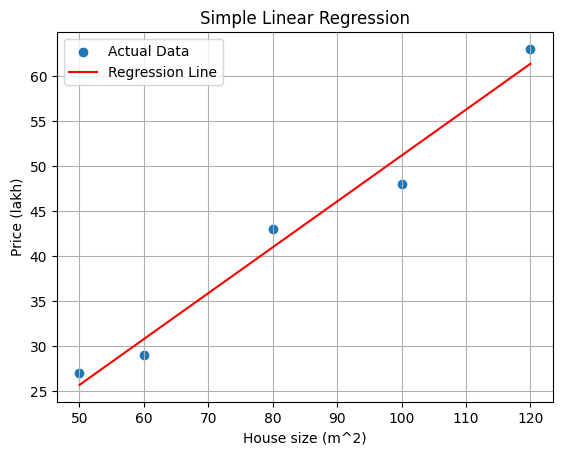

In [19]:
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

X = np.array([[50], [60], [80], [100], [120]])
y = np.array([27, 29, 43, 48, 63])

model = LinearRegression()
model.fit(X, y)


X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

#.reshape(-1, 1) -> Converts the generated values into the 2D shape expected by Scikit-Learn.

y_line = model.predict(X_line)


plt.scatter(X, y, label="Actual Data")
plt.plot(X_line, y_line, color="red", label="Regression Line")

plt.xlabel("House size (m^2)")
plt.ylabel("Price (lakh)")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(True)

## 2.5 — Multiple Linear Regression with Scikit-Learn

### 1. Definition
Multiple Linear Regression is a supervised learning algorithm that predicts a continuous target using two or more input features.

### 2. Mathematical Equation

ŷ = w₁x₁ + w₂x₂ + ... + wₙxₙ + b

- x₁, x₂, ..., xₙ: Input features
- w₁, w₂, ..., wₙ: Learned coefficients
- b: Learned intercept
- ŷ: Predicted target

### 3. Training a Model
The Scikit-Learn workflow remains the same as Simple Linear Regression:

- Create a `LinearRegression` estimator.
- Use `fit(X, y)` to learn the model parameters.
- Use `predict()` to generate predictions for new observations.

### 4. Understanding `coef_` and `intercept_`
- `coef_`: Contains one learned coefficient for each input feature.
- `intercept_`: Contains the learned intercept.

Each coefficient describes how the prediction changes when its corresponding feature increases by one unit, **holding the other features constant**.

### 5. Understanding Data Shapes
- `X.shape = (n_samples, n_features)`
- `y.shape = (n_samples,)`

For example, `X.shape = (30, 3)` means 30 observations and 3 input features.

For a single new observation with 3 features, the input shape should be `(1, 3)`.

**Important:** Keep the feature order consistent between training and prediction.

### 6. Interpreting Coefficients
- A positive coefficient means the predicted target increases as that feature increases, holding other features constant.
- A negative coefficient means the predicted target decreases under the same condition.
- Coefficients depend on the data, feature scales, and relationships between features.
- Correlated features and insufficient training data can make coefficients unstable.
- A coefficient does not necessarily represent a causal relationship.

### 7. Important Points
- Multiple Linear Regression uses several input features to predict one continuous target.
- Each feature has its own learned coefficient.
- More representative training data can improve parameter estimates, but more data does not guarantee correct coefficients.
- Evaluate the model on unseen data to assess its predictive performance.

**Key takeaway:** Multiple Linear Regression extends Simple Linear Regression by learning a coefficient for each input feature while keeping the same basic Scikit-Learn workflow.

In [20]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Features: size, bedrooms, age
X = np.array([
    [80,  2, 10],
    [100, 3,  5],
    [120, 3,  2],
    [150, 4,  8],
    [90,  2, 15],
    [110, 3,  7],
    [140, 4,  4],
    [75,  2, 12],
    [160, 4,  3],
    [95,  3,  9],
    [130, 3,  6],
    [180, 5,  5],
    [85,  2, 20],
    [115, 3,  3],
    [145, 4, 10],
    [105, 3, 12],
    [170, 4,  6],
    [70,  1,  8],
    [125, 3, 15],
    [155, 4,  2],
    [100, 2, 18],
    [135, 4,  7],
    [190, 5,  4],
    [88,  2,  6],
    [118, 3, 11],
    [148, 4,  5],
    [98,  2,  3],
    [165, 4, 12],
    [78,  2,  4],
    [200, 5,  1]
])

# Target: house price in lakh taka
y = np.array([
    40, 55, 70, 78, 38,
    58, 76, 35, 85, 49,
    65, 98, 32, 62, 73,
    50, 88, 29, 58, 82,
    39, 75, 105, 43, 57,
    79, 48, 83, 42, 112
])


model = LinearRegression()
model.fit(X, y)

print(f"Coefficients: {model.coef_}")
print(f"Intercept / Bias : {model.intercept_}")


#prediction
new_house = np.array([[110, 3, 5]])
prediction = model.predict(new_house)

print(f"Predicted Price : {prediction}")

Coefficients: [ 0.40814374  5.48764383 -0.75894619]
Intercept / Bias : 1.3737865729371066
Predicted Price : [58.93779818]


## 2.6 — Evaluating Regression Models with Scikit-Learn

### 1. Why Model Evaluation Is Necessary
Model evaluation measures how well a trained regression model predicts target values. Evaluating on unseen test data helps estimate how well the model generalizes to new observations.

### 2. Train-Test Split
- `train_test_split()` separates data into training and testing sets.
- The training set is used to train the model.
- The test set is used to evaluate predictions on unseen observations.
- An 80/20 split is a common starting point, not a strict rule.
- Split the data before fitting the model when evaluating generalization.

### 3. Mean Absolute Error (MAE)
MAE measures the average absolute difference between actual and predicted values.

- Lower MAE generally indicates better predictions.
- It uses the same units as the target variable.
- It is relatively easy to interpret.

### 4. Mean Squared Error (MSE)
MSE measures the average of squared prediction errors.

- Lower MSE generally indicates better predictions.
- Squaring errors penalizes large errors more heavily.
- Its units are the square of the target's units.

### 5. Root Mean Squared Error (RMSE)
RMSE is the square root of MSE.

- Lower RMSE generally indicates better predictions.
- It uses the same units as the target variable.
- It penalizes large errors more heavily than MAE.

### 6. R² Score
R², or the coefficient of determination, compares the model's predictions with a baseline that predicts the mean of the training targets.

- R² = 1: Perfect predictions on the evaluated data.
- R² = 0: No improvement over the mean-prediction baseline.
- R² < 0: Worse than that baseline.
- Higher R² is generally better when comparing models on the same evaluation data.

An R² of 0.85 does NOT mean 85% prediction accuracy.

### 7. Using Scikit-Learn Metrics
The `sklearn.metrics` module provides:

- `mean_absolute_error()` for MAE
- `mean_squared_error()` for MSE
- `root_mean_squared_error()` for RMSE in Scikit-Learn 1.4 and later
- `r2_score()` for R²

These functions compare actual target values with predicted values.

### 8. Important Points
- MAE, MSE, and RMSE measure prediction errors; lower values are generally better.
- R² measures performance relative to a baseline; higher values are generally better.
- Error magnitudes must be interpreted in the context of the target's scale.
- R² is not a percentage accuracy score.
- Evaluating on training data alone does not reliably measure generalization.
- Small test sets can produce unreliable performance estimates.
- Compare models using the same evaluation data and metrics.
- A simple baseline, such as `DummyRegressor`, helps determine whether a more complex model adds value.
- Cross-validation can provide a more stable assessment when data is limited.
- Keep the test set separate from model fitting and tuning to avoid misleading evaluation results.

**Key takeaway:** Use Scikit-Learn's evaluation metrics on appropriate held-out data to assess regression performance and understand how well a model may generalize to unseen observations.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import root_mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)


model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"MAE : {mean_absolute_error(y_test, y_pred)}")
print(f"MSE : {mean_squared_error(y_test, y_pred)}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred)}")
print(f"R^2 : {r2_score(y_test, y_pred)}")

MAE : 1.3055623047877074
MSE : 1.893493367449319
RMSE : 1.3760426473948106
R^2 : 0.9955473406997076


## 2.7 Underfitting and Overfitting in Regression

### Step 2 — Compare the Models

We compare polynomial degrees 1, 2, and 15 using training and testing RMSE.

| Degree | Training RMSE | Testing RMSE | Interpretation |
|---:|---:|---:|---|
| 1 | 1.939 | 2.169 | Underfitting |
| 2 | 1.504 | 1.940 | Best test performance |
| 15 | 1.348 | 1.951 | Possible overfitting |

- **Degree 1:** A straight line is too simple to capture the curved pattern.
- **Degree 2:** Captures the main pattern and achieves the lowest testing RMSE.
- **Degree 15:** Has lower training error but slightly higher testing error than degree 2.

**Key observation:** A more complex model can fit training data better without improving predictions on unseen data.

### Step 3 — Visualize the Fitted Curves

The graph helps us see how each polynomial model fits the observations.

- **Degree 1:** A straight line that misses the U-shaped pattern.
- **Degree 2:** A smooth curve that captures the main relationship.
- **Degree 15:** A highly flexible curve that may follow random noise and fluctuate excessively.

The plotting points are generated to draw smooth curves; they are not additional training observations.

### Takeaway

- **Underfitting:** The model is too simple to learn the underlying pattern.
- **Overfitting:** The model fits training data too closely and may generalize poorly.
- **Good generalization:** The model captures the main pattern and performs well on unseen data.

For this train/test split, degree 2 performs best because it has the lowest testing RMSE. These results alone do not prove severe overfitting.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

#create a non-linear dataset
np.random.seed(50)

X = np.linspace(-3, 3, 100).reshape(-1, 1)  #The reshape turns 1D to 2D, because sklearn expects 2D
y = 0.5 * X[:, 0]**2 + np.random.normal(0, 1.5, 100)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 50
)

print(f"Training Samples : {len(X_train)}")
print(f"Testing Samples : {len(X_test)}")

Training Samples : 80
Testing Samples : 20


In [10]:
degrees = [1, 2, 15]
results = {}

for degree in degrees:
    #generate ploynomial features
    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.fit_transform(X_test)

    #Train the model
    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    #Evaluate on training, testing data
    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)


    train_rmse = root_mean_squared_error(y_train, train_pred)
    test_rmse = root_mean_squared_error(y_test, test_pred)

    results[degree] = (train_rmse, test_rmse)

    print(f"Degree {degree}")
    print(f"Training RMSE: {train_rmse:.3f}")
    print(f"Testing RMSE:  {test_rmse:.3f}")
    print()
    

Degree 1
Training RMSE: 1.939
Testing RMSE:  2.169

Degree 2
Training RMSE: 1.504
Testing RMSE:  1.940

Degree 15
Training RMSE: 1.348
Testing RMSE:  1.951



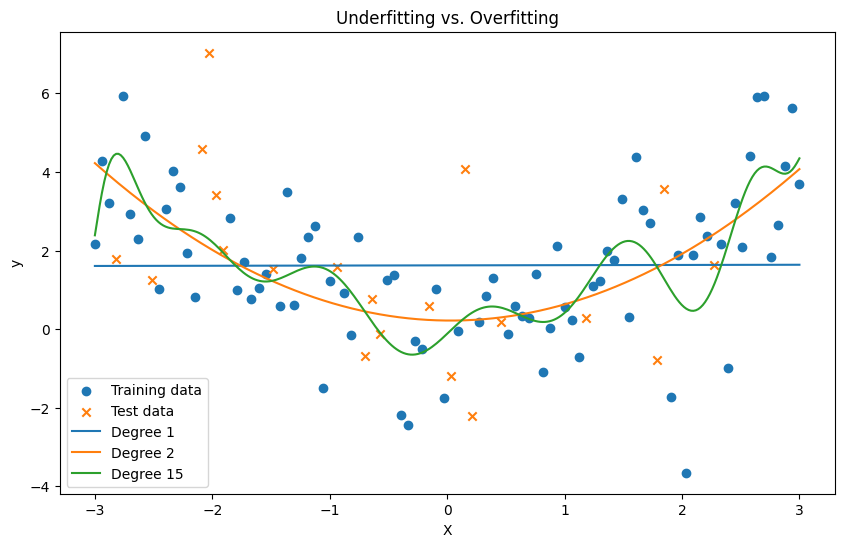

In [8]:

X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, label="Training data")
plt.scatter(X_test, y_test, label="Test data", marker="x")

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_plot = model.predict(poly.transform(X_plot))

    plt.plot(X_plot, y_plot, label=f"Degree {degree}")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Underfitting vs. Overfitting")
plt.legend()
plt.show()


## 2.8 Polynomial Regression with Scikit-Learn

### Why Use PolynomialFeatures?

Without `PolynomialFeatures`, Linear Regression learns:

ŷ = wx + b

This represents a straight-line relationship.

With `PolynomialFeatures(degree=2)`, an input such as `x = 3` becomes `[1, 3, 9]`, representing the bias, `x`, and `x²`.

The model can now learn:

ŷ = w₁x + w₂x² + b

This allows Linear Regression to learn curved relationships that a straight line cannot represent accurately.

**Example:** Our data follows `y = x² + 1`.

| x | Actual y |
|---:|---:|
| 1 | 2 |
| 2 | 5 |
| 3 | 10 |
| 4 | 17 |
| 5 | 26 |

The squared feature `x²` helps the model capture this pattern.

**Key takeaway:** `PolynomialFeatures` creates additional features, allowing Linear Regression to learn more complex patterns. It does not guarantee better predictions; excessive complexity can cause overfitting.

In [1]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X = [[1], [2], [3], [4], [5]]
y = [2, 5, 10, 17, 26]

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

print(X_poly)    #(bias, x, x^2)

[[ 1.  1.  1.]
 [ 1.  2.  4.]
 [ 1.  3.  9.]
 [ 1.  4. 16.]
 [ 1.  5. 25.]]


In [4]:
model = LinearRegression()
model.fit(X_poly, y)

print(f"Coefficient : {model.coef_.round(4)}")
print(f"Intercept : {model.intercept_.round(4)}")

Coefficient : [ 0. -0.  1.]
Intercept : 1.0


In [8]:
X_new = [[6], [7], [8]]
X_new_poly = poly.transform(X_new)

prediction = model.predict(X_new_poly)

print(f"Prediction : {prediction}")

Prediction : [37. 50. 65.]


### Why Use `transform()` Instead of `fit_transform()` on New Data?

- `fit_transform(X_train)` — learns the transformation and applies it to the training data.
- `transform(X_new)` — applies the same fitted transformation to new data.

Using `fit_transform(X_new)` fits the transformer again, which is unnecessary.

With `PolynomialFeatures`, this doesn't change the result because it simply generates polynomial features such as `x` and `x²`.

However, with transformers such as `StandardScaler`, fitting again on new data changes the learned mean and standard deviation, potentially making predictions inconsistent with the training process.

**Best practice:** Fit preprocessing transformers on training data, then reuse them with `transform()` for test data and new inputs.